<a href="https://colab.research.google.com/github/Gloou-ui/NM/blob/main/%D0%9B%D0%A03_%D0%9B%D0%B8%D1%82%D0%B2%D0%B8%D0%BD_%D0%9C%D0%B8%D1%80%D0%BE%D1%81%D0%BB%D0%B0%D0%B2_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

!wget -q -O home_value.zip https://www.kaggle.com/api/v1/datasets/download/prokshitha/home-value-insights
!unzip -o home_value.zip -d home_value_data

import os

print(os.listdir("home_value_data"))


Archive:  home_value.zip
  inflating: home_value_data/house_price_regression_dataset.csv  
['house_price_regression_dataset.csv']


## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [2]:
csv_files = [f for f in os.listdir("home_value_data") if f.endswith(".csv")]

df = pd.read_csv("home_value_data/" + csv_files[0])

print("Розмір датасету:", df.shape)
display(df.head())

Розмір датасету: (1000, 8)


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [3]:
print("Перші 5 рядків:")
display(df.head())

print("\nРозмір:")
print(df.shape)

print("\nТипи даних:")
print(df.dtypes)

print("\nСтруктура:")
df.info()

Перші 5 рядків:


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06



Розмір:
(1000, 8)

Типи даних:
Square_Footage            int64
Num_Bedrooms              int64
Num_Bathrooms             int64
Year_Built                int64
Lot_Size                float64
Garage_Size               int64
Neighborhood_Quality      int64
House_Price             float64
dtype: object

Структура:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [4]:
print("Кількість дубльованих рядків:", df.duplicated().sum())

Кількість дубльованих рядків: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [5]:
print("Пропущені значення:")
display(df.isnull().sum())

Пропущені значення:


,0
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [6]:
display(df.describe())

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [7]:
print("Частоти Neighborhood_Quality:")
display(df["Neighborhood_Quality"].value_counts().sort_index())

Частоти Neighborhood_Quality:


,count
Neighborhood_Quality,
1,91
2,105
3,85
4,99
5,109
6,101
7,102
8,97
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

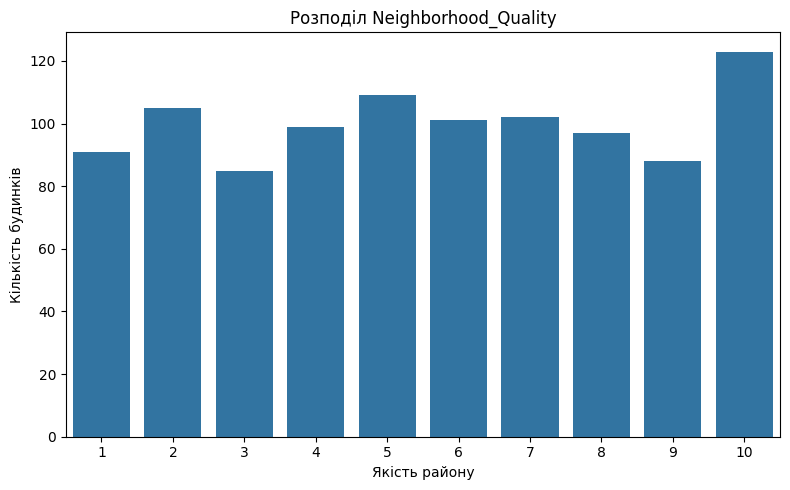

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Neighborhood_Quality"
)

plt.title("Розподіл Neighborhood_Quality")
plt.xlabel("Якість району")
plt.ylabel("Кількість будинків")
plt.tight_layout()
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [9]:
print("Частоти Num_Bathrooms:")
display(df["Num_Bathrooms"].value_counts().sort_index())

Частоти Num_Bathrooms:


,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

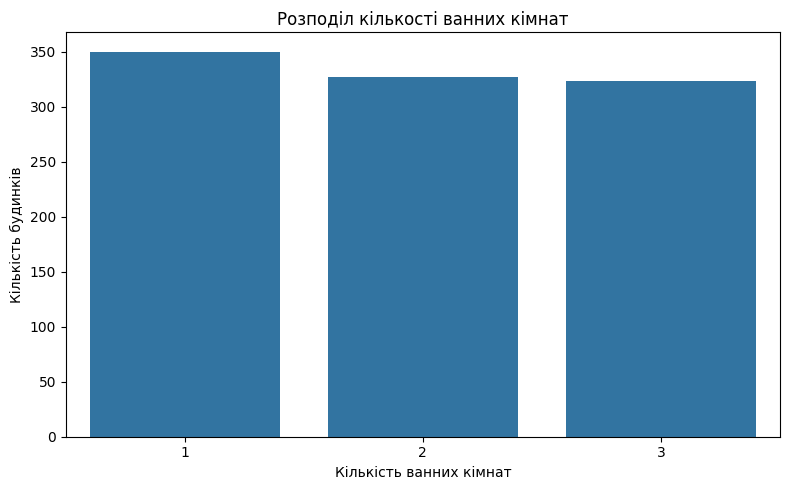

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Num_Bathrooms"
)

plt.title("Розподіл кількості ванних кімнат")
plt.xlabel("Кількість ванних кімнат")
plt.ylabel("Кількість будинків")
plt.tight_layout()
plt.show()

### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

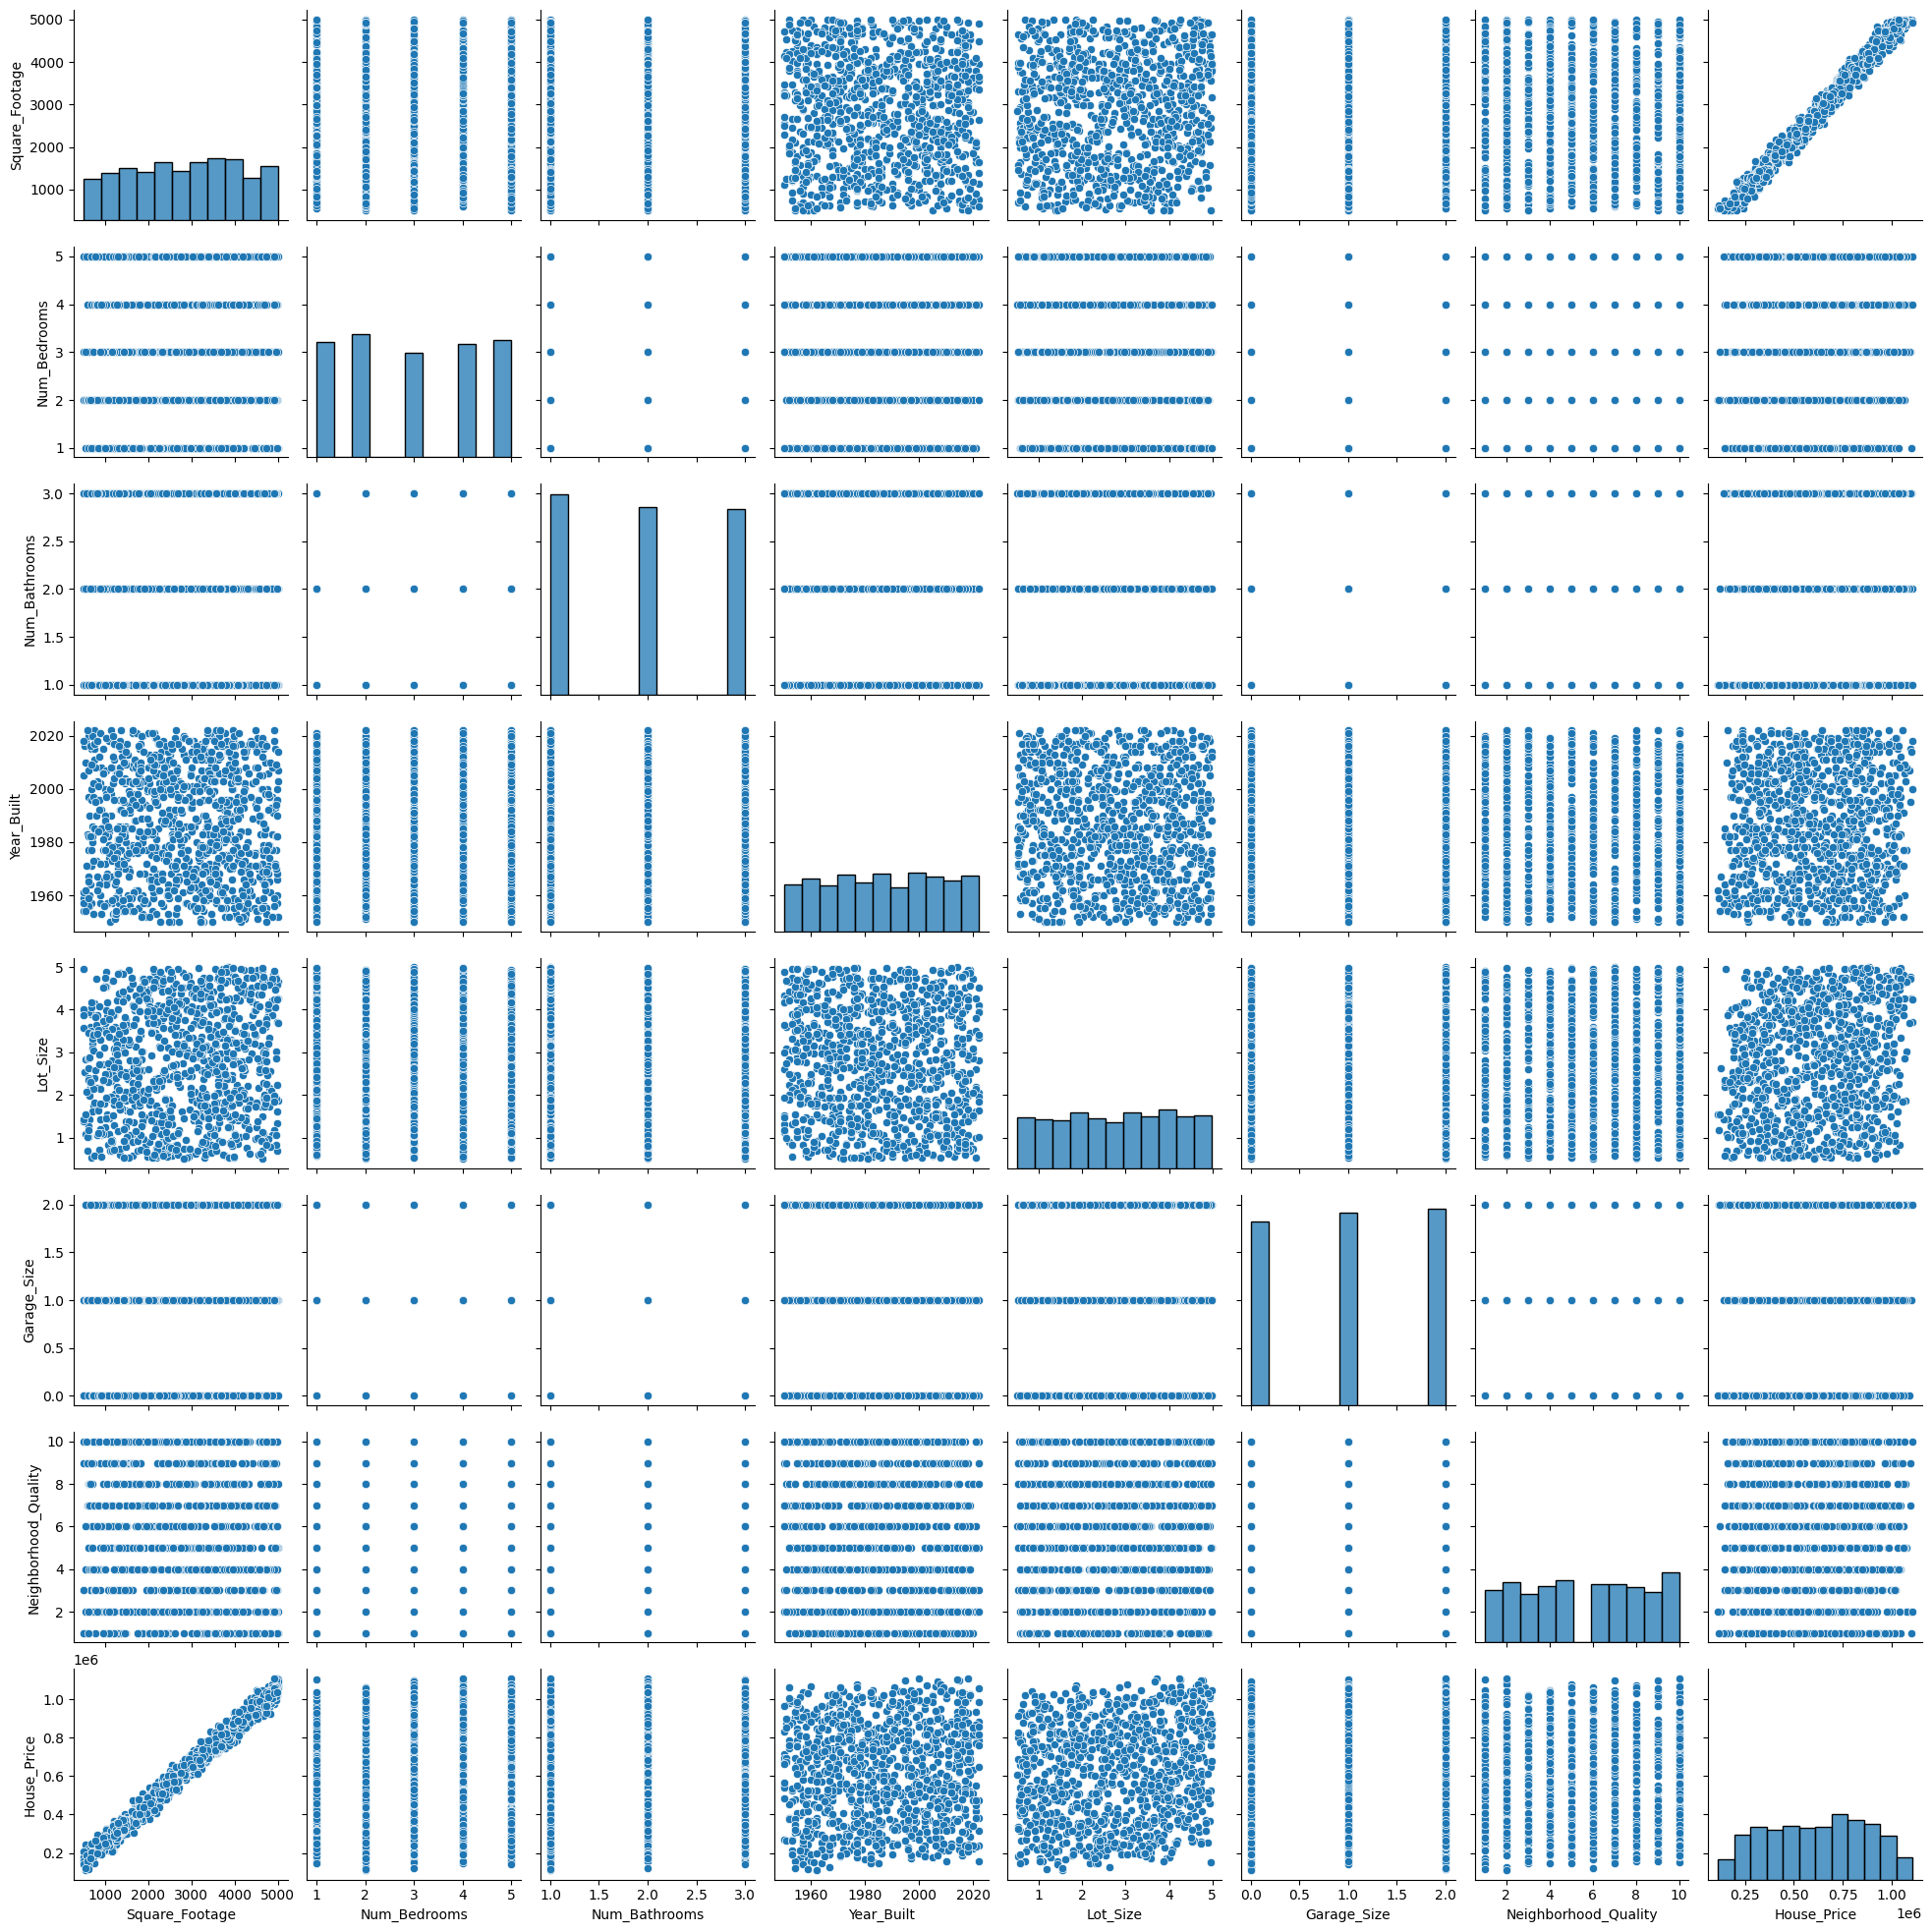

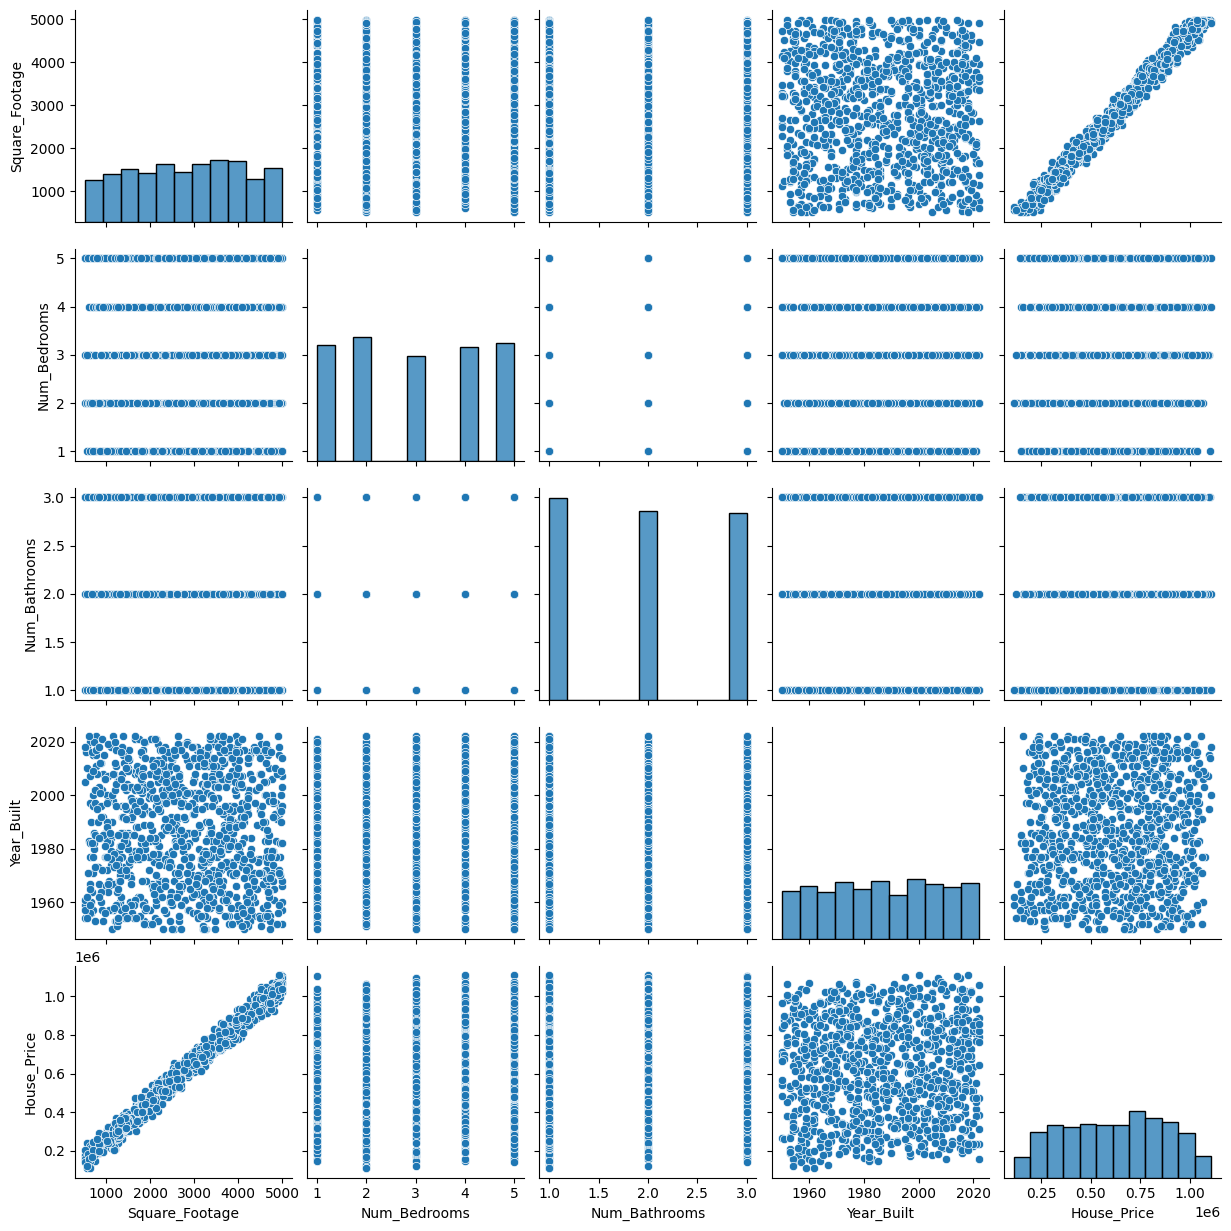

In [12]:
sns.pairplot(df)

plt.show()
sns.pairplot(
    df[
        [
            "Square_Footage",
            "Num_Bedrooms",
            "Num_Bathrooms",
            "Year_Built",
            "House_Price"
        ]
    ]
)

plt.show()

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

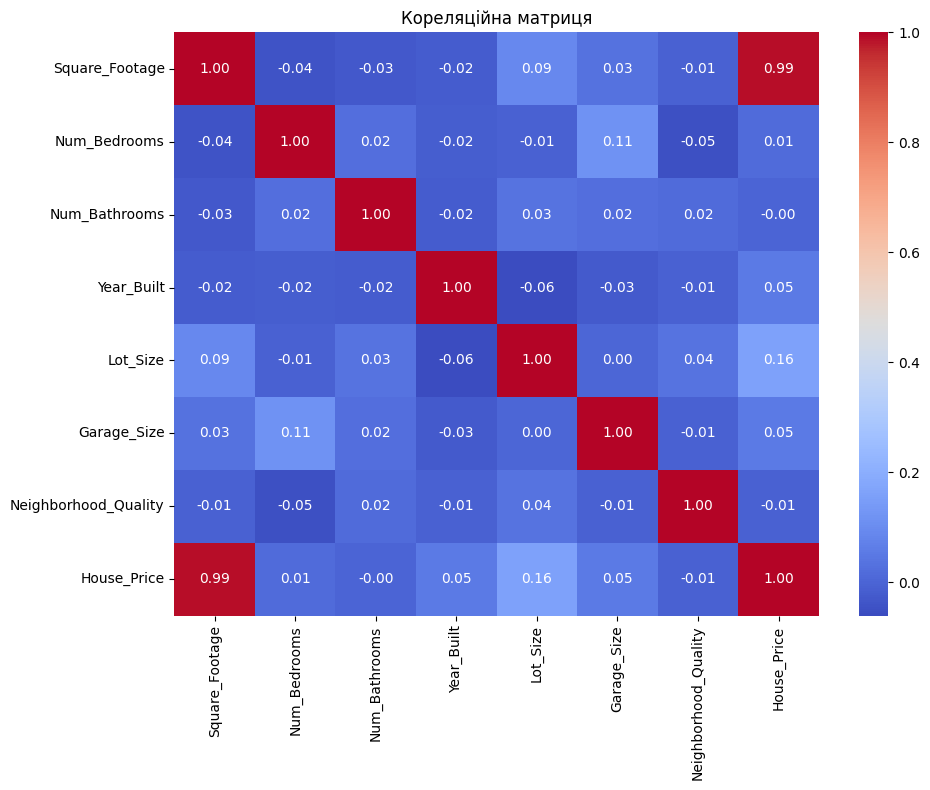

In [13]:
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Кореляційна матриця")
plt.tight_layout()
plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [14]:
price_corr = (
    df.corr(numeric_only=True)["House_Price"]
    .sort_values(ascending=False)
)

display(price_corr.to_frame("Кореляція з House_Price"))

,Кореляція з House_Price
House_Price,1.000000
Square_Footage,0.991261
Lot_Size,0.160412
Garage_Size,0.052133
Year_Built,0.051967
Num_Bedrooms,0.014633
Num_Bathrooms,-0.001862
Neighborhood_Quality,-0.007770


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [15]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [16]:
X = df.drop(columns=["House_Price"])
y = df["House_Price"]

print("X:")
display(X.head())

print("\ny:")
display(y.head())

X:


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality
0,1360,2,1,1981,0.599637,0,5
1,4272,3,3,2016,4.753014,1,6
2,3592,1,2,2016,3.634823,0,9
3,966,1,2,1977,2.730667,1,8
4,4926,2,1,1993,4.699073,0,8



y:


,House_Price
0,2.623829e+05
1,9.852609e+05
2,7.779774e+05
3,2.296989e+05
4,1.041741e+06


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

Розмір навчальної вибірки: (800, 7)
Розмір тестової вибірки: (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [18]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ]),

    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso())
    ]),

    "Random Forest": RandomForestRegressor(
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

print("Створені моделі:")
print(list(models.keys()))

Створені моделі:
['Linear Regression', 'Ridge', 'Lasso', 'Random Forest', 'Gradient Boosting']


### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [21]:
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    results.append([
        name,
        r2,
        mae,
        mse
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Модель",
        "R²",
        "MAE",
        "MSE"
    ]
)

results_df = results_df.sort_values(
    "R²",
    ascending=False
).reset_index(drop=True)

display(results_df)


,Модель,R²,MAE,MSE
0,Linear Regression,0.998426,8174.583600,1.014348e+08
1,Lasso,0.998426,8174.748374,1.014366e+08
2,Ridge,0.998410,8241.586911,1.024810e+08
3,Gradient Boosting,0.996510,12305.217615,2.249656e+08
4,Random Forest,0.993886,16114.289644,3.941317e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

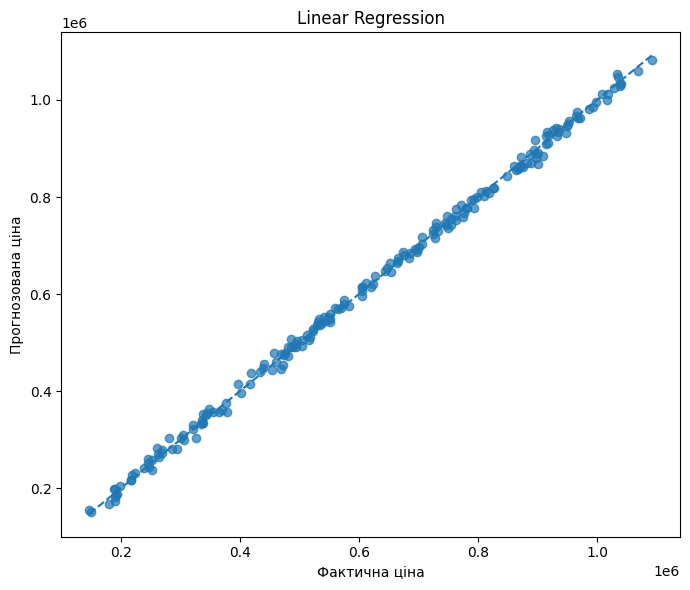

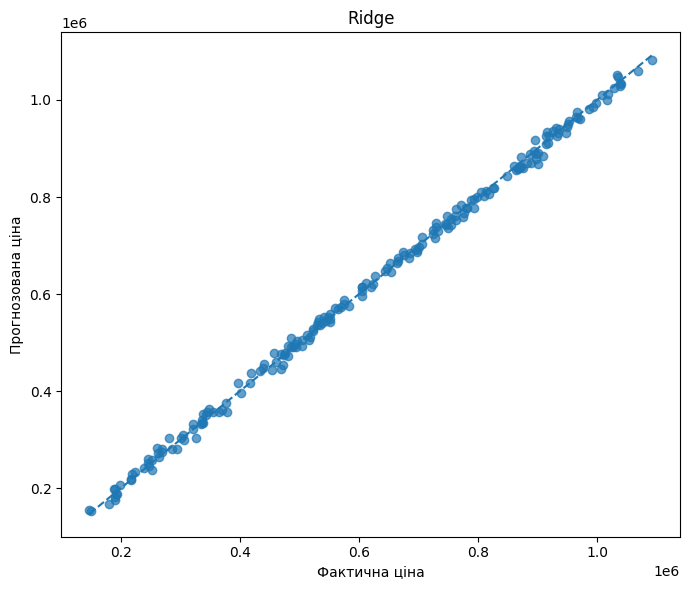

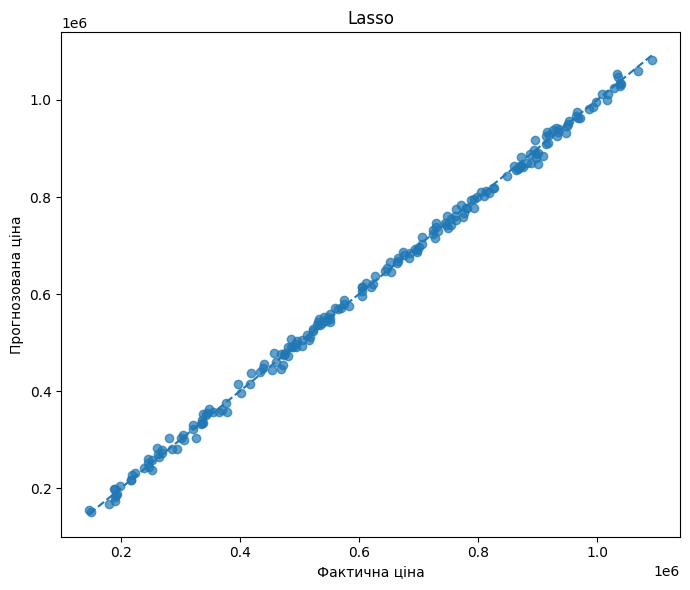

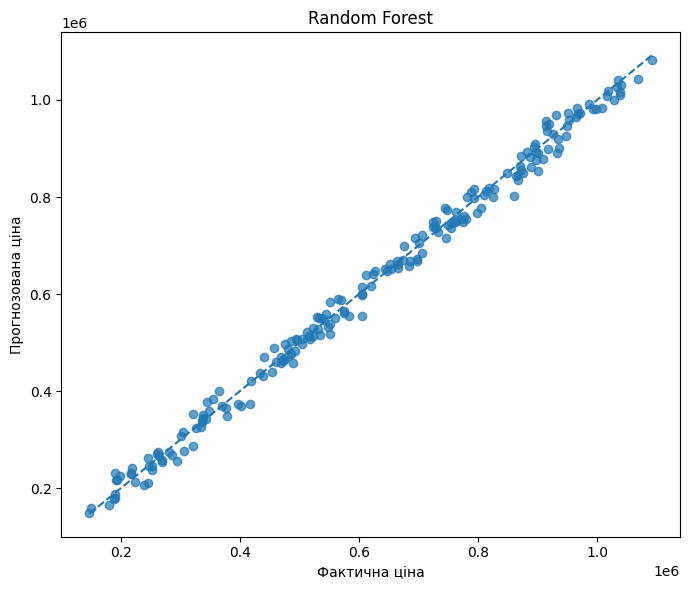

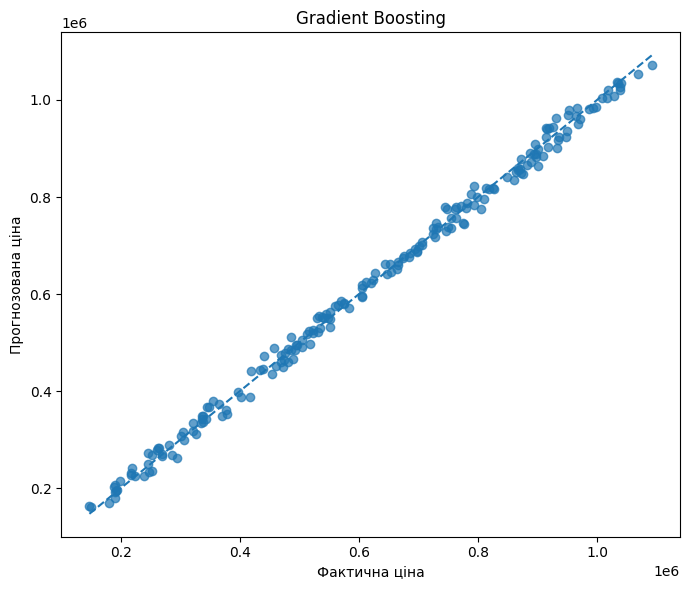

In [22]:
for name, y_pred in predictions.items():

    plt.figure(figsize=(7, 6))

    plt.scatter(
        y_test,
        y_pred,
        alpha=0.7
    )

    min_value = min(y_test.min(), y_pred.min())
    max_value = max(y_test.max(), y_pred.max())

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    plt.xlabel("Фактична ціна")
    plt.ylabel("Прогнозована ціна")
    plt.title(name)

    plt.tight_layout()
    plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [24]:
rf = RandomForestRegressor(
    random_state=42
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_features": ["sqrt", 1.0],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20],
                         'max_features': ['sqrt', 1.0],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='r2')

### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [25]:
best_rf = RandomForestRegressor(
    **grid_search.best_params_,
    random_state=42
)

best_rf.fit(X_train, y_train)

y_pred_best_rf = best_rf.predict(X_test)

best_rf_r2 = r2_score(y_test, y_pred_best_rf)
best_rf_mae = mean_absolute_error(y_test, y_pred_best_rf)
best_rf_mse = mean_squared_error(y_test, y_pred_best_rf)

print("Оптимізований Random Forest")
print("R²:", best_rf_r2)
print("MAE:", best_rf_mae)
print("MSE:", best_rf_mse)

Оптимізований Random Forest
R²: 0.9940298846807288
MAE: 15930.637875446102
MSE: 384826810.1531117


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [26]:
base_rf = models["Random Forest"]

y_pred_base_rf = predictions["Random Forest"]

base_rf_r2 = r2_score(y_test, y_pred_base_rf)
base_rf_mae = mean_absolute_error(y_test, y_pred_base_rf)
base_rf_mse = mean_squared_error(y_test, y_pred_base_rf)

rf_comparison = pd.DataFrame({
    "Модель": [
        "Random Forest",
        "Optimized Random Forest"
    ],
    "R²": [
        base_rf_r2,
        best_rf_r2
    ],
    "MAE": [
        base_rf_mae,
        best_rf_mae
    ],
    "MSE": [
        base_rf_mse,
        best_rf_mse
    ]
})

display(
    rf_comparison.style.format({
        "R²": "{:.4f}",
        "MAE": "{:.2f}",
        "MSE": "{:.2f}"
    })
)

,Модель,R²,MAE,MSE
0,Random Forest,0.9939,16114.29,394131747.45
1,Optimized Random Forest,0.9940,15930.64,384826810.15


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

Зміна R²: 0.00014435467387319267
Зміна MAE: -183.65176849154523
Зміна MSE: -9304937.292922556

як висновок, оптимізація покращила якість Random Forest, R² збільшився, а MAE та MSE зменшились, тож так, доцільно використовувати оптимізовану модель.

In [31]:
r2_change = best_rf_r2 - base_rf_r2
mae_change = best_rf_mae - base_rf_mae
mse_change = best_rf_mse - base_rf_mse

print("Зміна R²:", r2_change)
print("Зміна MAE:", mae_change)
print("Зміна MSE:", mse_change)


Зміна R²: 0.00014435467387319267
Зміна MAE: -183.65176849154523
Зміна MSE: -9304937.292922556


## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [29]:
linear_model = models["Linear Regression"]

linear_predictions = predictions["Linear Regression"]

prediction_table = pd.DataFrame({
    "Фактична ціна": y_test.values,
    "Прогнозована ціна": linear_predictions
})

prediction_table["Похибка у відсотках"] = (
    abs(
        prediction_table["Фактична ціна"] -
        prediction_table["Прогнозована ціна"]
    )
    / prediction_table["Фактична ціна"]
) * 100
random_10 = prediction_table.sample(
    n=10,
    random_state=42
)

display(
    random_10.style.format({
        "Фактична ціна": "{:.2f}",
        "Прогнозована ціна": "{:.2f}",
        "Похибка у відсотках": "{:.2f}%"
    })
)

,Фактична ціна,Прогнозована ціна,Похибка у відсотках
95,1068538.11,1059729.02,0.82%
15,194353.74,187868.55,3.34%
30,270230.64,279715.82,3.51%
158,986006.86,981949.27,0.41%
128,953339.73,957382.95,0.42%
115,914555.75,909764.27,0.52%
69,746167.73,742469.14,0.50%
170,646766.29,654445.55,1.19%
174,523323.07,524605.44,0.25%
45,1008539.16,1011343.64,0.28%


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**